# T02: Visualizing Reconstructions in napari

This tutorial demonstrates how to render neuronal reconstructions in [napari](https://napari.org/), the multi-dimensional image viewer for Python, using PySNT's built-in converters. Basic familiarity with napari is helpful but not required.

```{hint}
By the end of this notebook, you will be able to:
- Render a reconstruction in napari as centerlines, nodes, or a surface mesh with accurate local thickness
- Color-code reconstructions by any SNT measurement
- Overlay reconstructions on their source image
- Know how to round-trip tracings between napari and SNT with the napari-snt plugin

**Estimated Time**: 10-15 minutes
```

```{note}
Make sure to read [Tutorial 01](./01_single_cell_analysis.ipynb) before running this notebook.
```

````{warning}
**Extra Requirements:** This tutorial requires [napari](https://napari.org/). It is installed by PySNT's `napari` extra:

```bash
python -m pip install "pysnt[napari]"
```

If you are using the pixi setup of the [installation guide](../install.md), run `pixi run pip install "pysnt[napari]"` instead.
````

```{note}
napari requires Qt6, which is installed by the `napari` extra (PyQt6). If you get `ImportError: napari requires Qt >= 6...` or a crash mentioning the Qt platform plugin, another package in your environment is interfering: see [Quirks and Limitations](../limitations.md#napari-and-qt-bindings).
```

## Setup and Initialization

As in previous tutorials, we start by initializing pysnt. We then load the *OP_1* cell from the [DIADEM challenge](https://diadem.janelia.org/challenge.html), one of SNT's demo datasets:

In [1]:
import pysnt
pysnt.initialize()

snt_service = pysnt.SNTService()
tree = snt_service.demoTree('OP1')

```{hint}
See [Tutorial 01](./01_single_cell_analysis.ipynb) for pointers on how to load local files.
```

## Converters

PySNT provides three converters that turn a `Tree` into the arrays napari expects, one per napari layer type:

| Converter | Returns | napari layer |
| --------- | ------- | ------------ |
| `tree_to_napari_paths()` | One polyline per path | Shapes |
| `tree_to_napari_points()` | Node coordinates and radii | Points |
| `tree_to_napari_surface()` | Vertices, faces, and radii (or colors) | Surface |

```{note}
SNT uses XYZ coordinates, whereas napari uses ZYX ordering. The converters take care of this: all returned coordinates are in napari's ZYX order, in SNT's spatial units (typically µm).
```

## Visualizing Centerlines: Shapes Layer

This is the most straightforward way to visualize tracings in napari: Render each path as a centerline with a single color:

2026-11-03 16:36:21.992 python[80760:4322658] [JRSAppKitAWT markAppIsDaemon]: Process manager already initialized: can't fully enable headless mode.


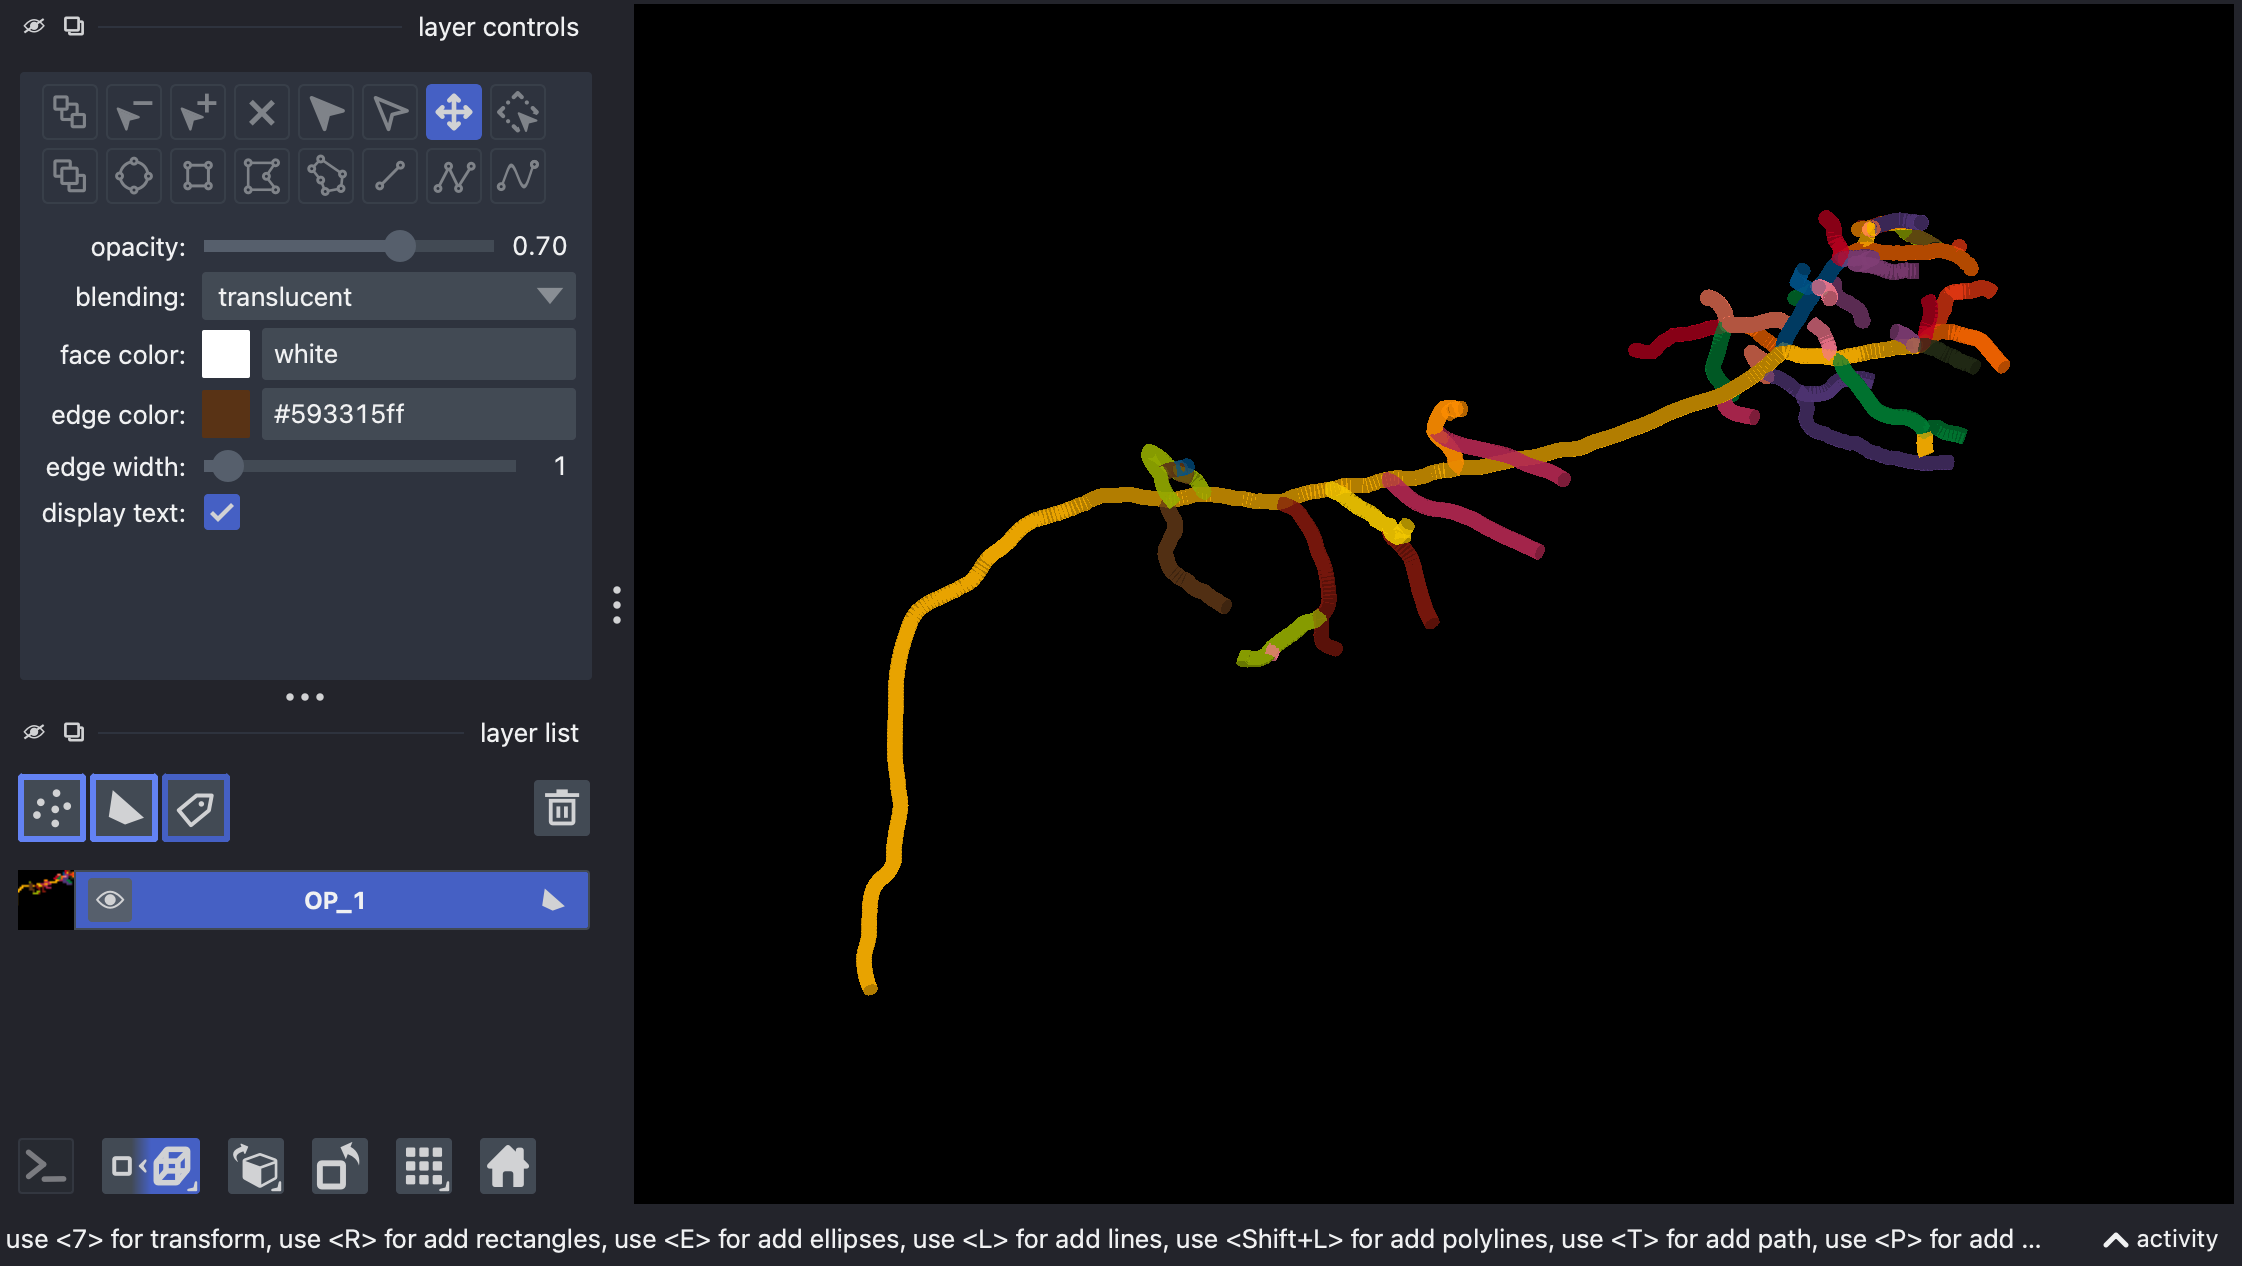

In [2]:
import napari
from napari.utils import nbscreenshot
from pysnt import tree_to_napari_paths
from pysnt.util import SNTColor

paths = tree_to_napari_paths(tree)

# Assign distinct colors to each path: We can use SNT's contrast
# colors as hex strings, as long as we remove the alpha channel
# (last 2 characters) from each hex string.
path_colors = SNTColor.getDistinctColorsHex(len(paths), 'dim') # Skip dim hues
path_colors = [color[:-2] for color in path_colors]

# Create viewer without showing window, in 3D mode
viewer = napari.Viewer(show=False)
viewer.dims.ndisplay = 3

# Add all paths to a single napari layer
paths_layer = viewer.add_shapes(
    paths,
    shape_type='path',
    edge_color=path_colors,
    edge_width=1,
    name=tree.getLabel(),
)

# Fit the scene to the viewer and take a snapshot
viewer.reset_view()
nbscreenshot(viewer)

## Visualizing Nodes: Points Layer

The _paths_ layer doesn't support variable width along a path. For rendering local thicknesses, the simplest (but least accurate) strategy is to render each node as a sphere. By default, nodes without a valid radius are discarded (`valid_only=True`), which is common in reconstructions that lack radii:

1544 nodes, radii range: 0.099884 to 1.539689


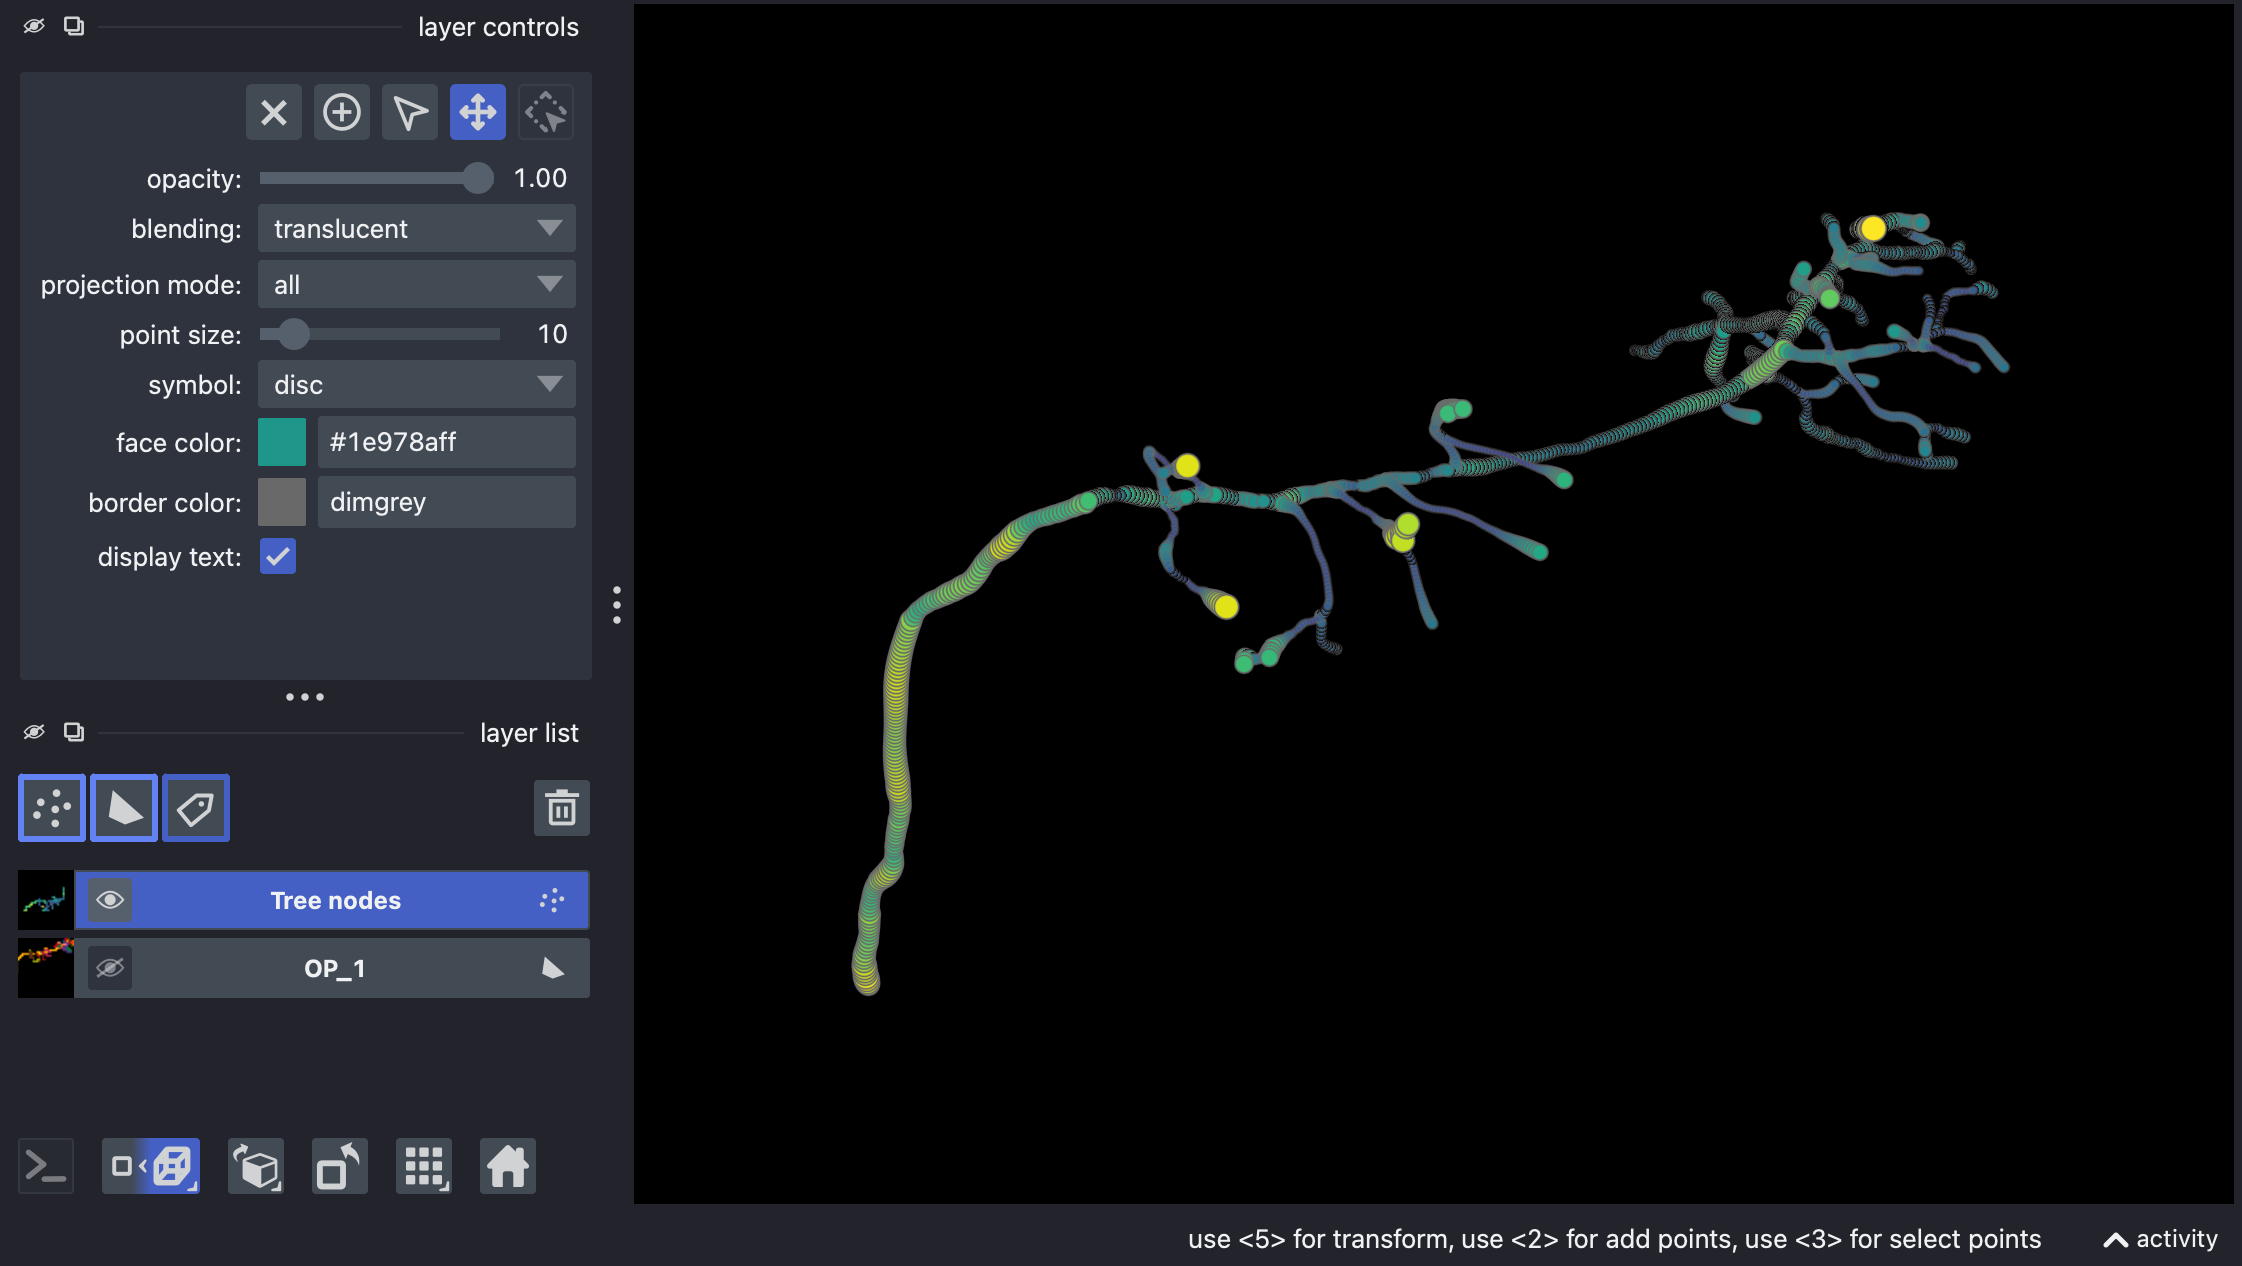

In [3]:
from pysnt import tree_to_napari_points

coords, radii = tree_to_napari_points(tree)
print(f"{len(coords)} nodes, radii range: {radii.min()} to {radii.max()}")

nodes_layer = viewer.add_points(
    coords,
    size=2 * radii,
    features={'radii': radii},  # Store radii as a feature
    face_color='radii',  # Color by the radius feature
    face_colormap='viridis',
    name='Tree nodes'
)

paths_layer.visible = False
nbscreenshot(viewer)

## Visualizing Surfaces: Surface Layer

Surface meshes represent local thickness most accurately: every segment between two nodes is rendered as a truncated cone whose end radii match those of the nodes:

Vertices: 23920, Faces: 23920


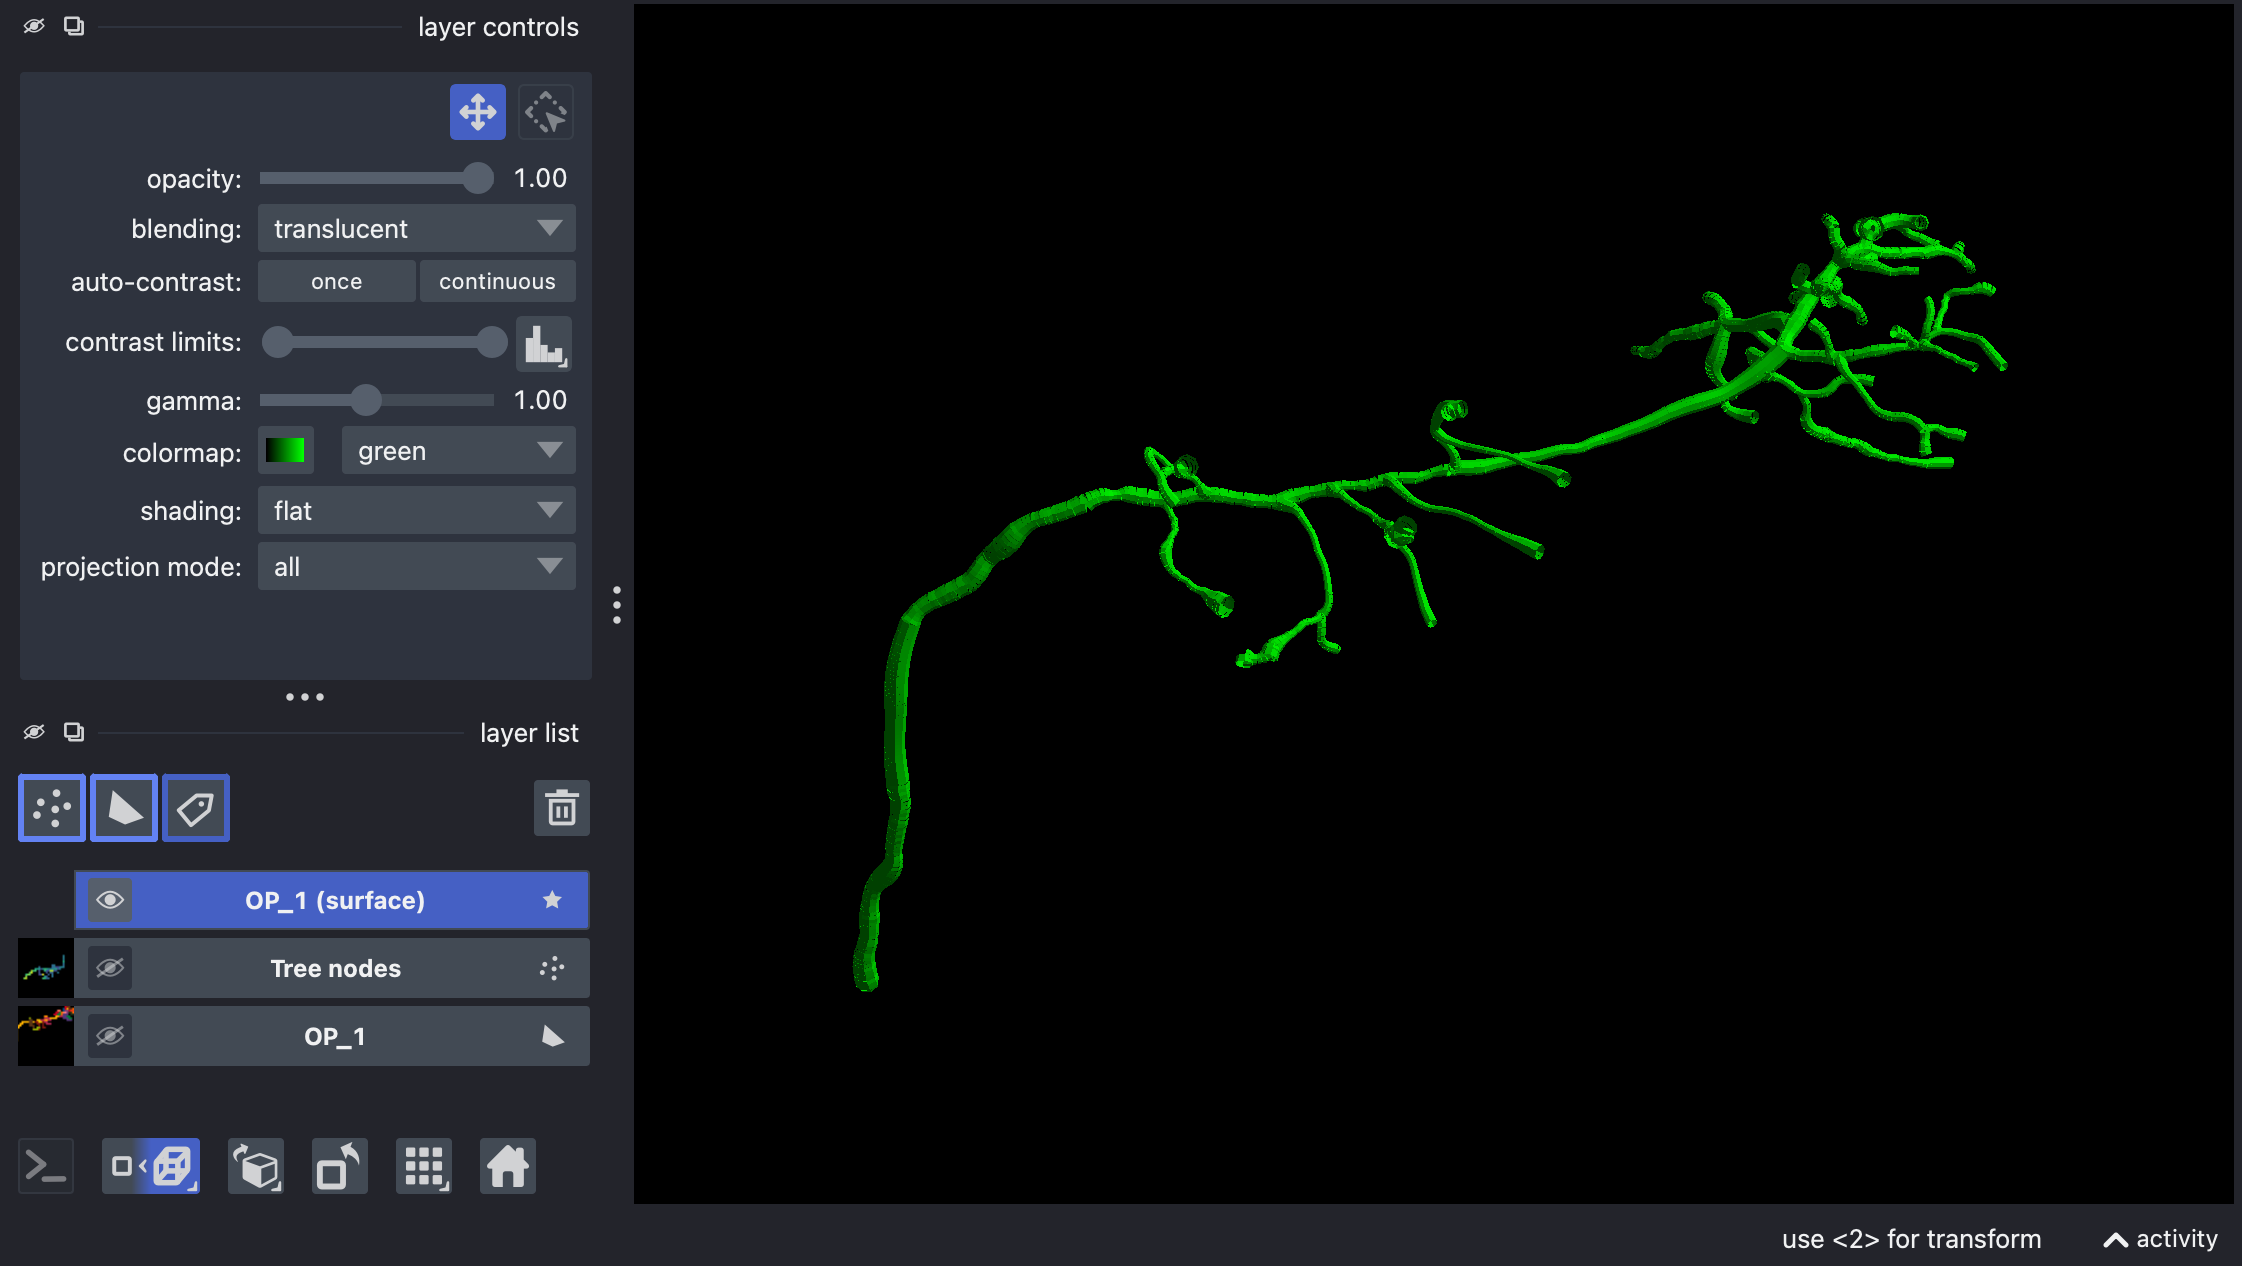

In [4]:
from pysnt import tree_to_napari_surface

vertices, faces, radii = tree_to_napari_surface(tree)
print(f"Vertices: {len(vertices)}, Faces: {len(faces)}")

surface_layer = viewer.add_surface(
    (vertices, faces),
    colormap='green',
    name=f'{tree.getLabel()} (surface)'
)

nodes_layer.visible = False
nbscreenshot(viewer)

The third element returned by the converter holds the radius of each vertex, which allows us to color-code the surface by thickness using any napari colormap:

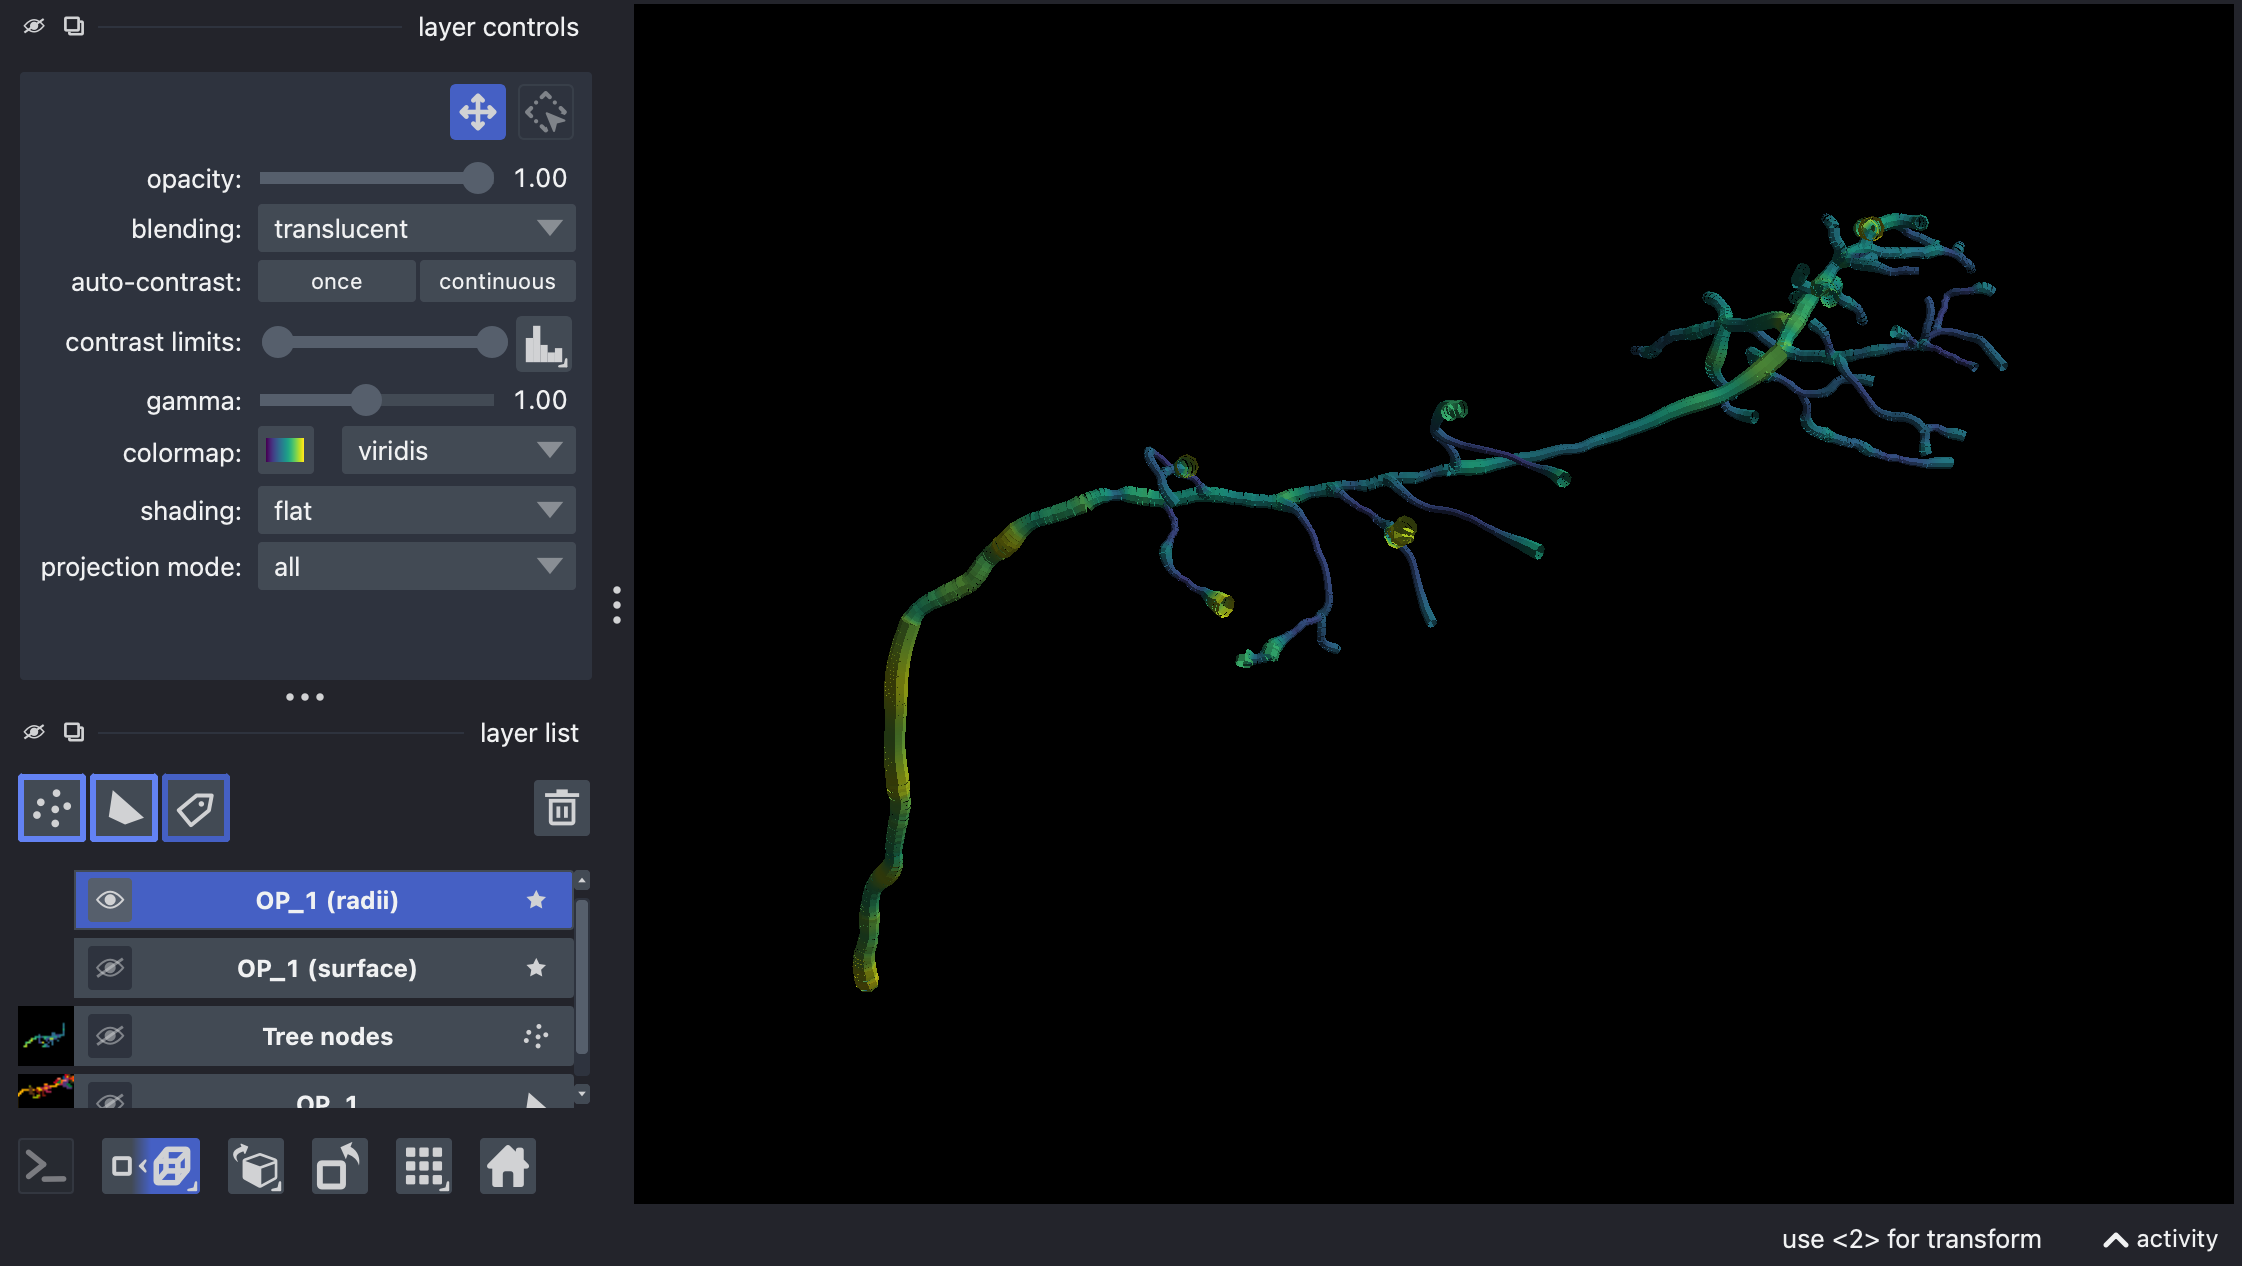

In [5]:
radii_layer = viewer.add_surface(
    (vertices, faces, radii),
    colormap='viridis',
    name=f'{tree.getLabel()} (radii)'
)

surface_layer.visible = False
nbscreenshot(viewer)

```{tip}
Use `n_sides` to control the smoothness of the mesh (default: 8), and `min_radius` to render reconstructions that lack radii, which would otherwise be invisible (e.g., `tree_to_napari_surface(tree, min_radius=0.5)`).
```

## Mapping Measurements

As mentioned in [Tutorial 01](./01_single_cell_analysis.ipynb), we can 'overlay' measurements on the reconstruction itself, by means of a `ColorMapper` that maps quantitative traits to the Tree. Setting `colors=True` makes the converter return the node colors produced by {class}`TreeColorMapper <pysnt.analysis.TreeColorMapper>` as per-vertex RGBA values, instead of radii:

[SNTUtils] Retrieving org.scijava.Context...

[INFO] [SNTUtils] 104 scijava services loaded


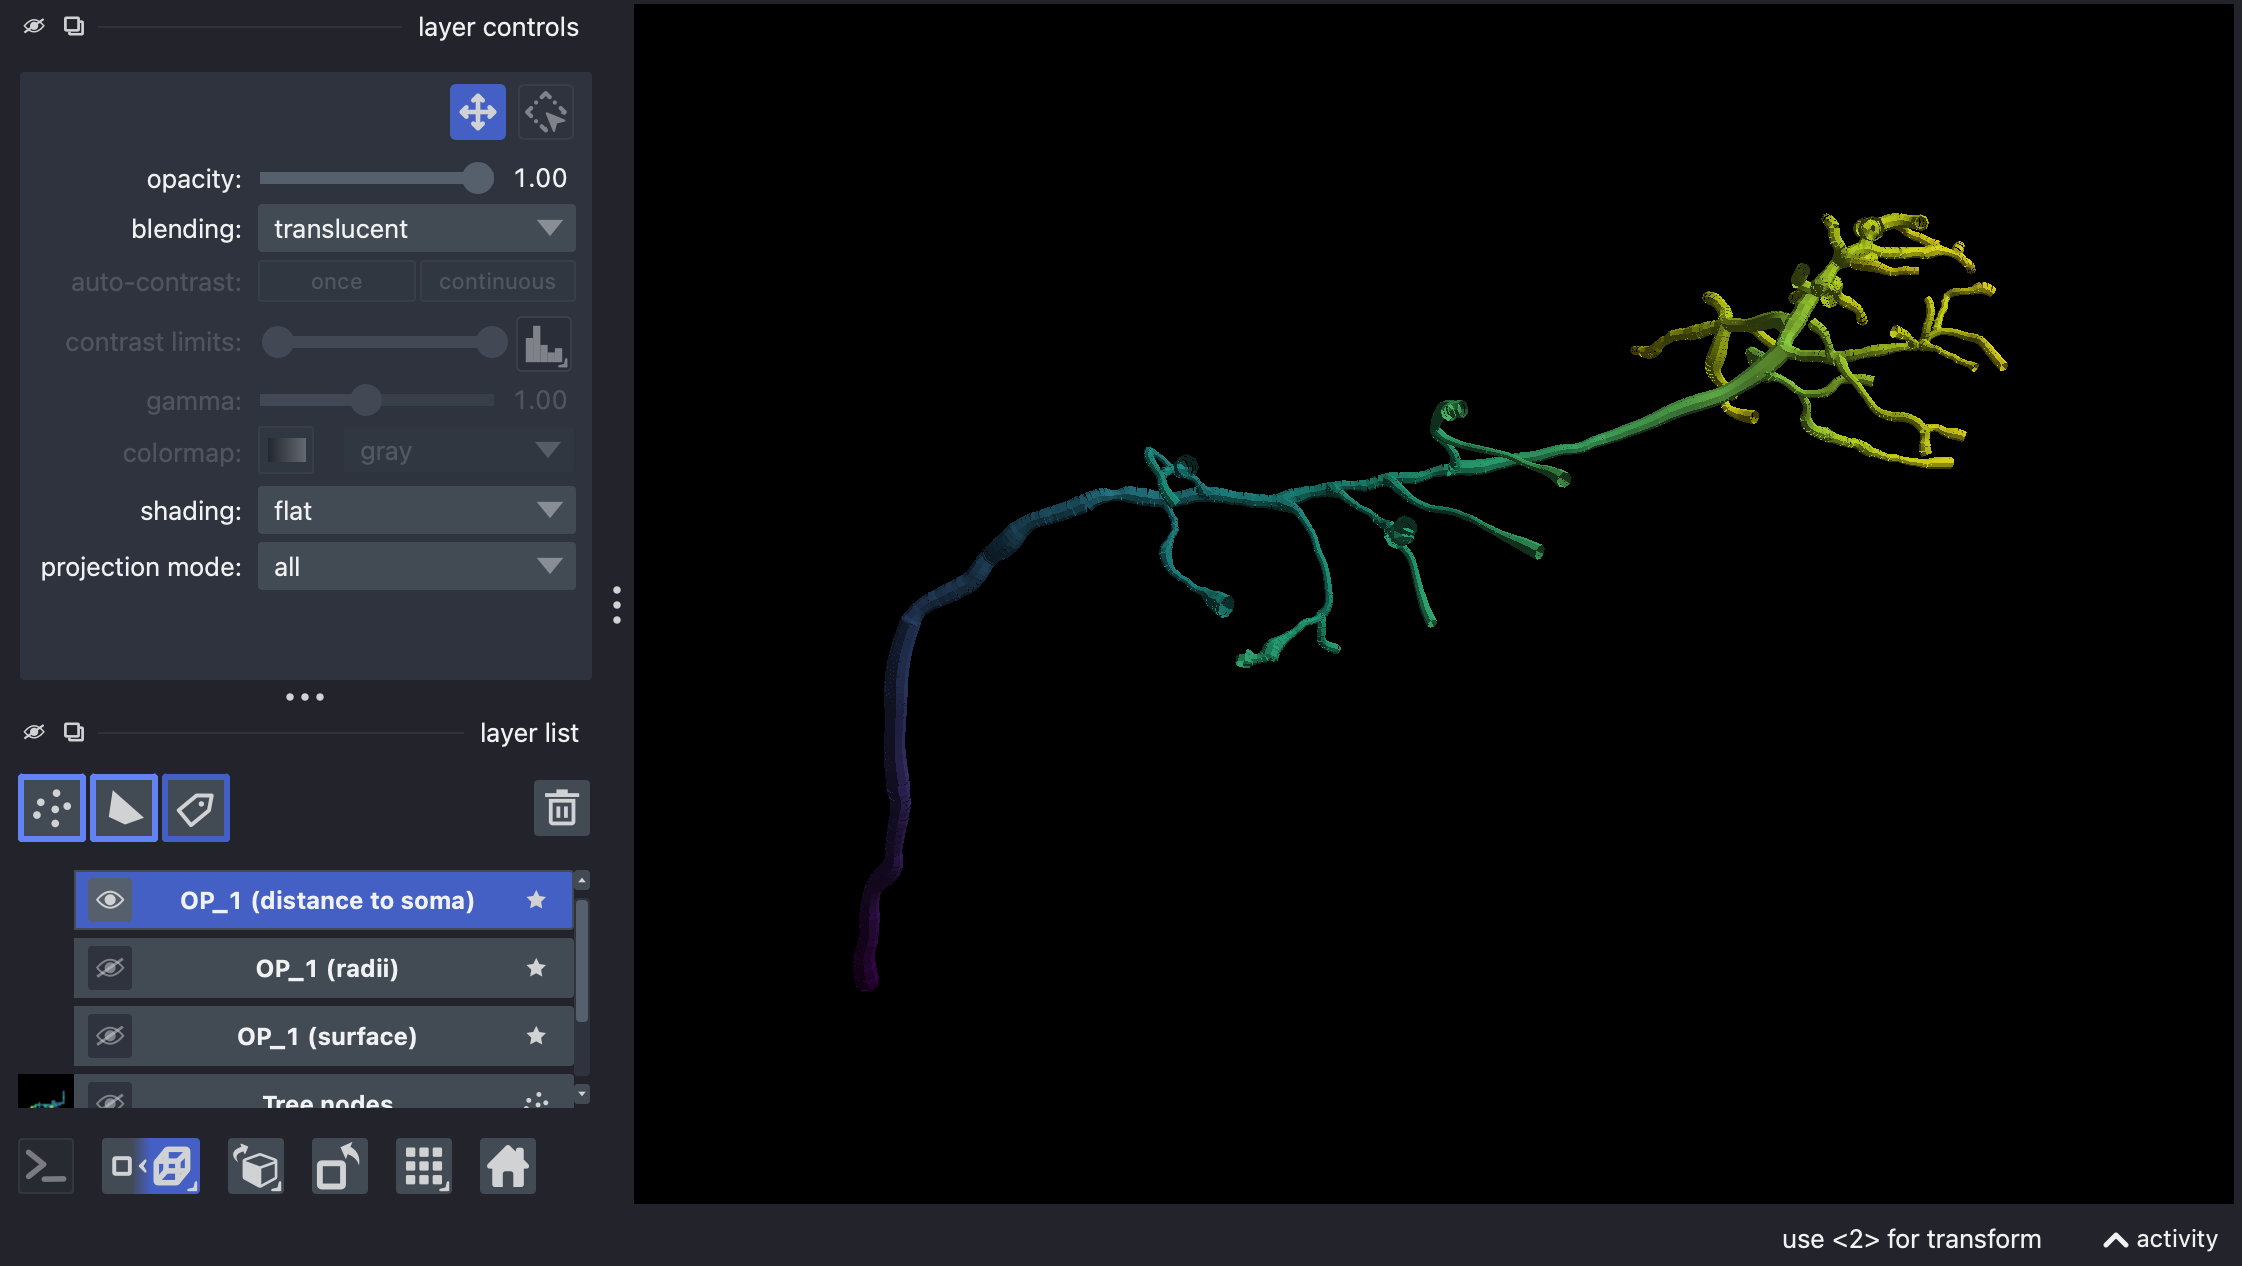

In [6]:
from pysnt.analysis import TreeColorMapper

# Map a metric to the tree: tree, metric, lut/colormap (case-sensitive)
color_mapper = TreeColorMapper()
metric = 'distance to soma'
color_mapper.map(tree, metric, 'viridis')

vertices, faces, colors = tree_to_napari_surface(tree, colors=True)
mapped_layer = viewer.add_surface((vertices, faces), name=f'{tree.getLabel()} ({metric})')
mapped_layer.vertex_colors = colors  # Set vertex colors directly on the layer

radii_layer.visible = False
nbscreenshot(viewer)

And, of course, we can adapt to any of the supported mappings:

In [7]:
print(color_mapper.getMetrics())

[Internode angle, Internode distance, No. of branch points, No. of nodes, No. of spines/varicosities, Node radius, Path spine/varicosity density, Path distance to soma, Path extension angle, Path extension angle (Rel.), Path extension angle XY, Path extension angle XZ, Path extension angle ZY, Path frame, Path length, Path mean radius, Path order, Sholl inters. (root centered), Horton-Strahler orders, Tags/filename, Node intensity values, X coordinates, Y coordinates, Z coordinates]


Creating a convenience function is probably the best strategy:

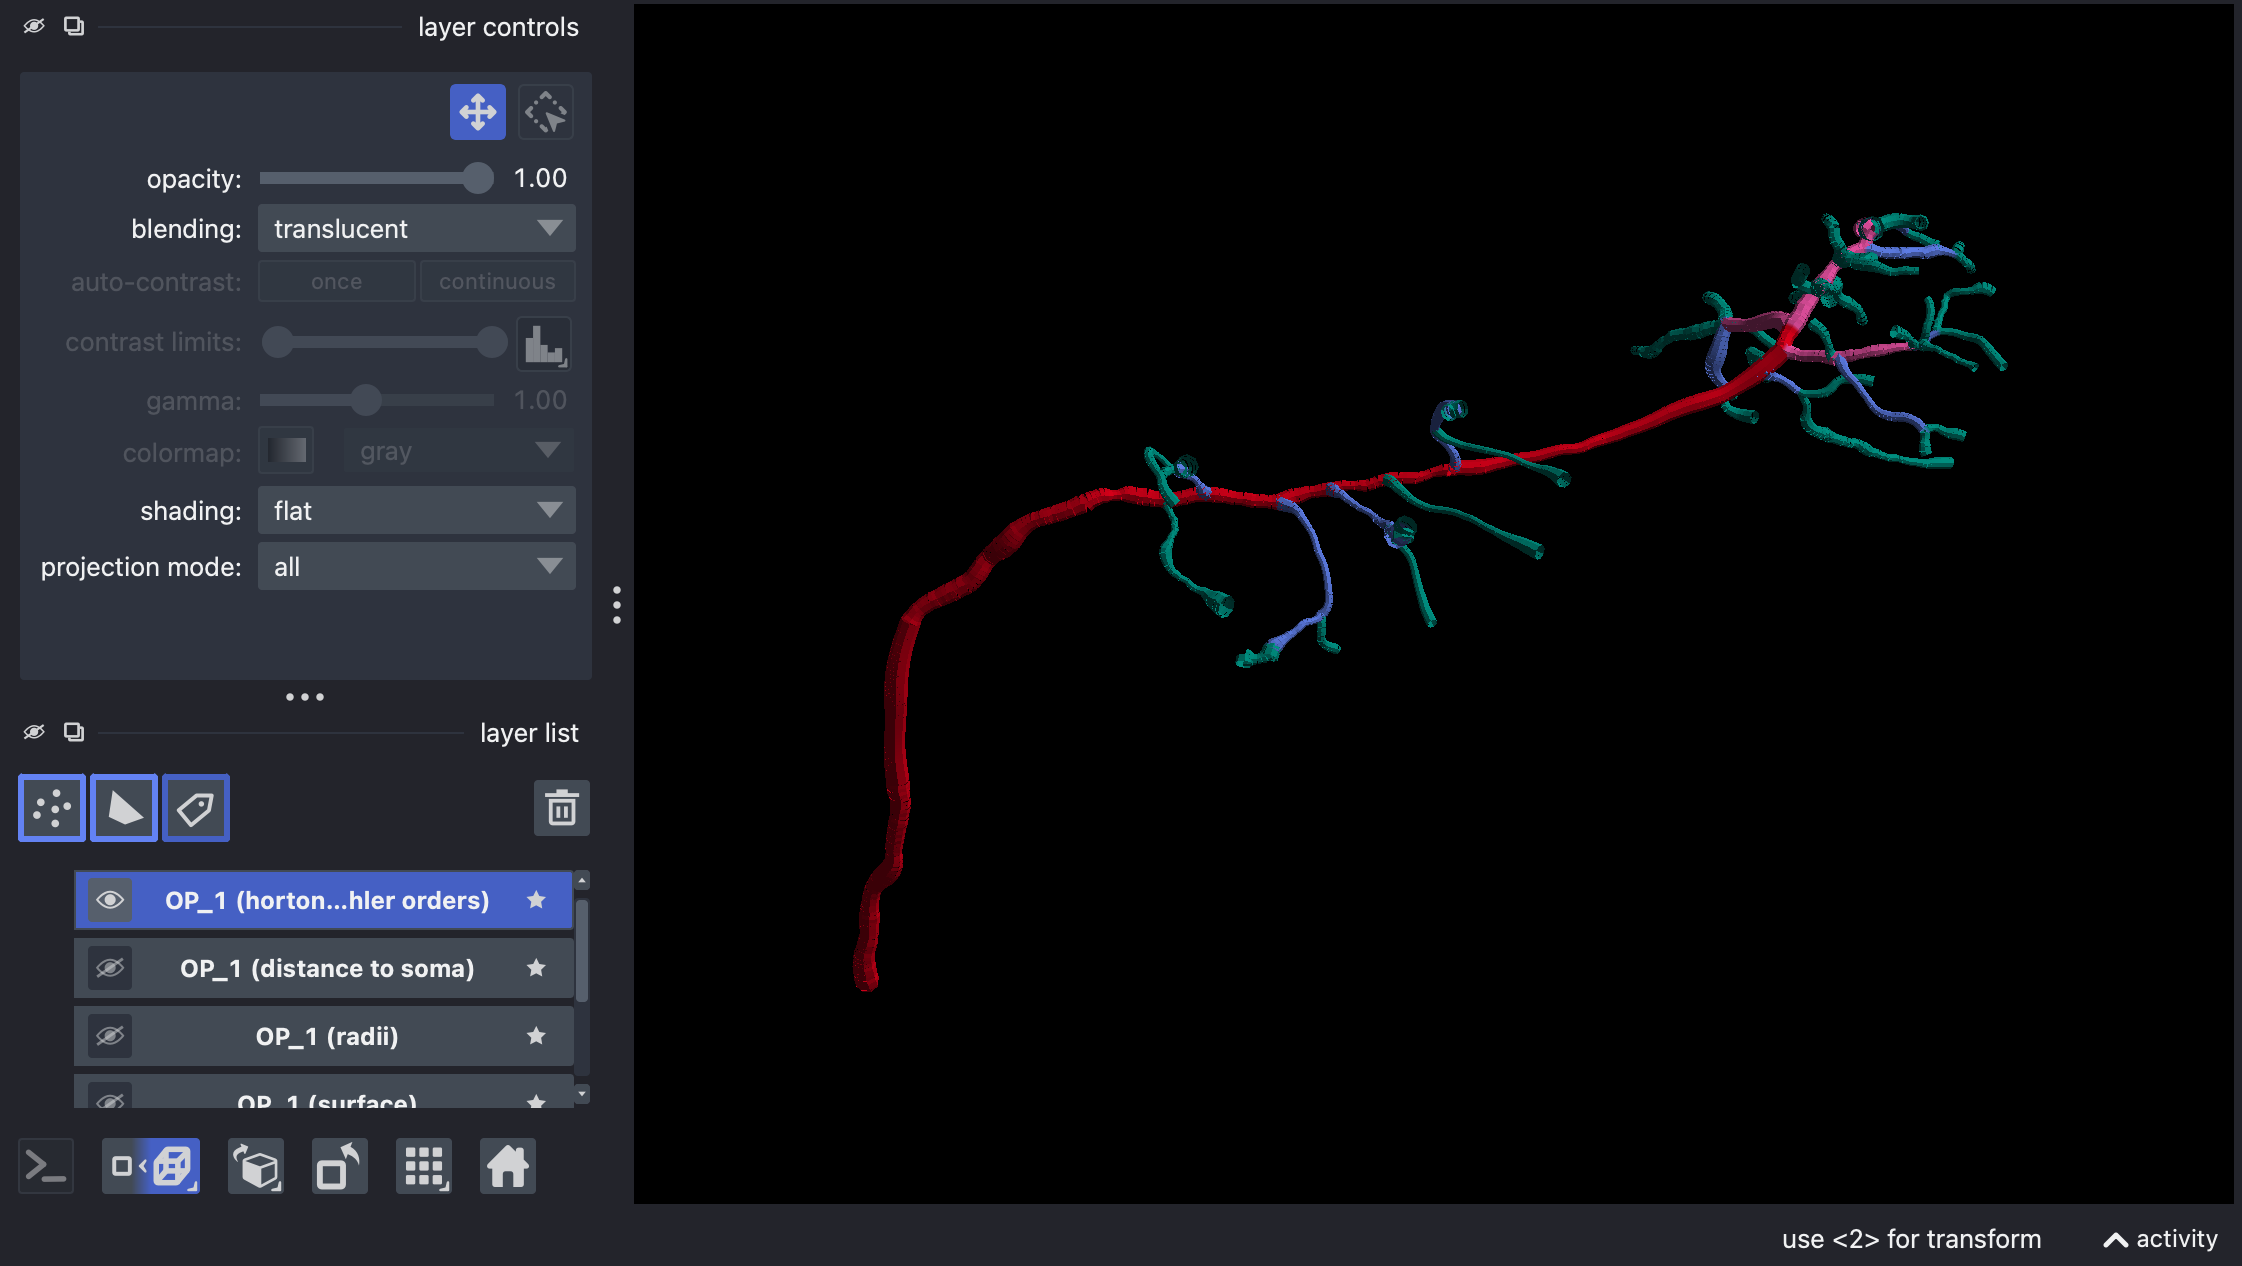

In [8]:
def color_mapped_surface(viewer, tree, metric, lut='ice'):
    """Add a surface layer color-coded by an SNT metric."""
    color_mapper = TreeColorMapper()
    color_mapper.unMap(tree)  # Discard previous mappings
    color_mapper.map(tree, metric, lut)
    vertices, faces, colors = tree_to_napari_surface(tree, colors=True)
    layer = viewer.add_surface((vertices, faces), name=f'{tree.getLabel()} ({metric})')
    layer.vertex_colors = colors
    return layer


strahler_layer = color_mapped_surface(viewer, tree, 'horton-strahler orders', 'ice')
mapped_layer.visible = False
nbscreenshot(viewer)

## Loading Imagery

Most images generated by SNT are retrieved as ImageJ/Scijava images, either `ImagePlus` or `Dataset` objects. These can be converted to data arrays using pysnt's underlying pyimagej instance. Setting the layer's `scale` to the image calibration ensures image and reconstruction share the same space:

Operating in headless mode - the original ImageJ will have limited functionality.


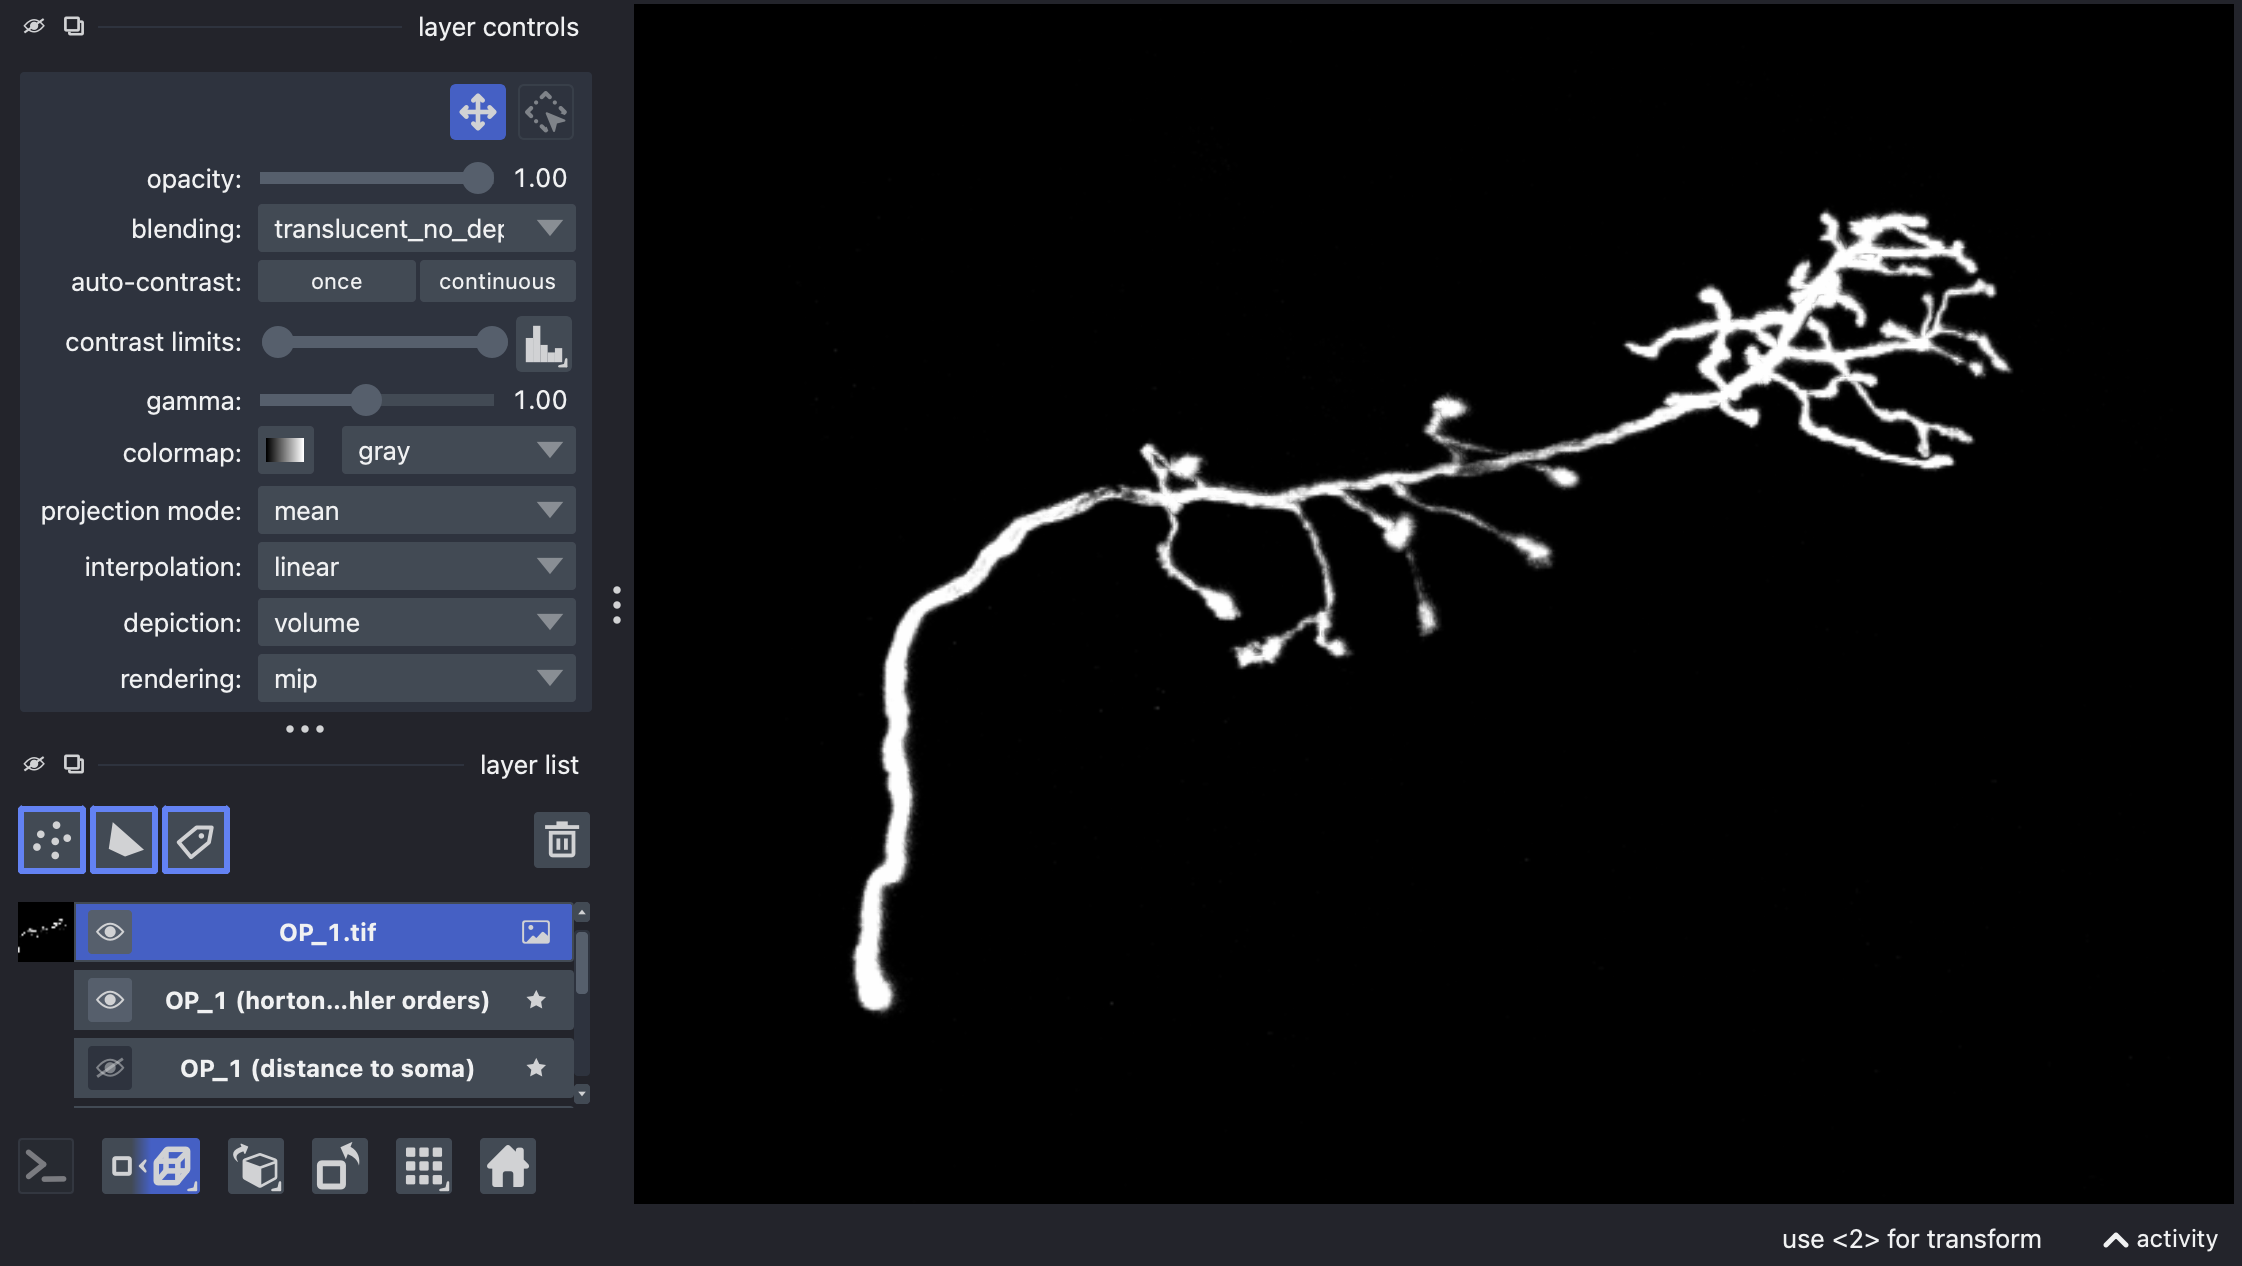

In [9]:
# Obtain demo image (ImagePlus object) associated
# with the OP1 reconstruction from pysnt.SNTService
img = snt_service.demoImage('OP1')
cal = img.getCalibration()

# Convert ImagePlus to xarray DataArray using pyimagej
image_xarray = pysnt.ij().py.from_java(img)

img_layer = viewer.add_image(
    image_xarray.values,
    name=img.getTitle(),
    rendering='mip',
    colormap='gray',
    scale=(cal.pixelDepth, cal.pixelHeight, cal.pixelWidth)  # ZYX
)
nbscreenshot(viewer)

## Round Trip with SNT: napari-snt

The converters above are one-way: they render PySNT reconstructions in napari. To go the other way, e.g., to trace structures in napari and continue in SNT, you can use [napari-snt](https://github.com/morphonets/napari-snt), a napari plugin that sends polylines drawn in napari to SNT and receives SNT's paths back as napari Shapes. Unlike the converters, it needs SNT 5.0.23 or newer running in a local Fiji, so it can't be run from a notebook. To use it:

1. Install the plugin (it is not yet available from PyPI):

   ```bash
   python -m pip install git+https://github.com/morphonets/napari-snt
   ```

2. Draw polylines in a Shapes layer (or place ordered points in a Points layer).
3. Open *Plugins > SNT Bridge (napari-snt)*, pick the layer, and click *Open in SNT*.
4. Use *Import SWC...* to bring paths exported by SNT back into napari.

See the plugin's [README](https://github.com/morphonets/napari-snt#readme) for details on calibration and branching.

In [10]:
# Environment this notebook was last run with
import datetime, platform, re
import napari, qtpy
from scyjava import jimport

snt_v = re.sub(r"(-SNAPSHOT-[0-9a-f]{7})[0-9a-f]+", r"\1", str(pysnt.snt_version()))
java_v = jimport("java.lang.System").getProperty("java.version")
print(f"Last run: {datetime.date.today():%Y-%m-%d}")
print(f"PySNT {pysnt.version()} | SNT {snt_v}")
print(f"Python {platform.python_version()} | Java {java_v} | {platform.system()} {platform.machine()}")
print(f"napari {napari.__version__} | Qt {qtpy.QT_VERSION} ({qtpy.API_NAME})")

Last run: 2026-11-03
PySNT 5.0.0.dev0 | SNT 5.0.24-SNAPSHOT-98112b1
Python 3.12.16 | Java 21.0.10 | Darwin arm64
napari 0.10.0 | Qt 6.12.0 (PyQt6)


## Cleanup

Now that the tutorial is complete, we can dispose of all resources:

In [11]:
viewer.close() # Close napari
pysnt.dispose() # Dispose PySNT resources and shutdown the JVM

```{note}
On macOS, a Python icon may remain in the Dock after `viewer.close()`. In a notebook, napari closes its windows but keeps the underlying Qt application alive (so that new viewers can be created). The icon goes away when the kernel is shut down or restarted.
```

## Summary

In this tutorial, we rendered PySNT reconstructions in napari using the converters provided by PySNT:

1. **Centerlines** with `tree_to_napari_paths()` and napari's Shapes layer
2. **Nodes** with `tree_to_napari_points()` and napari's Points layer, with sizes proportional to radii
3. **Surface meshes** with `tree_to_napari_surface()`, which represent local diameter variations accurately
4. **Color-mapped surfaces** using `colors=True` together with SNT's `TreeColorMapper`
5. **Image overlay** by converting ImageJ images to arrays with pyimagej

We also saw how napari-snt can be used to round-trip tracings between napari and SNT.

## Data Sources and References

Data used in this notebook is part of SNT's demo datasets. In particular, the *OP_1* [dataset](https://diadem.janelia.org/olfactory_projection_fibers_readme.html). The relevant publications associated with this dataset are:

- Brown KM, Barrionuevo G, Canty AJ, et al. The DIADEM data sets: representative light microscopy images of neuronal morphology to advance automation of digital reconstructions. Neuroinformatics. 2011;9(2-3):143-157. doi:[10.1007/s12021-010-9095-5](https://doi.org/10.1007/s12021-010-9095-5)

- Jefferis GS, Potter CJ, Chan AM, et al. Comprehensive maps of Drosophila higher olfactory centers: spatially segregated fruit and pheromone representation. Cell. 2007;128(6):1187-1203. doi:[10.1016/j.cell.2007.01.040](https://doi.org/10.1016/j.cell.2007.01.040)

See [SNT citation](https://imagej.net/plugins/snt/faq#how-do-i-cite-snt) for details on how to properly cite SNT.